# Sextans A — Resumen integral del filtro V

### Chips 1–8 · Fotometría de apertura y **incertidumbre porcentual del flujo**

**Universidad de los Andes · Trabajo de tesis · Octubre de 2026**

Este cuaderno consolida los resultados **reportados para los ocho segmentos del filtro V**, desde la detección `DAOFIND` hasta la comparación entre fotometría de anillo fijo y adaptativo. Se han convertido los errores fotométricos `MERR` de magnitudes a **incertidumbre relativa del flujo en porcentaje**, de modo que las tablas y las gráficas de calidad sean más intuitivas.

**Alcance:** únicamente filtro V. Chips 1–2: procesamiento supervisado; chips 3–8: procesamiento automático con `sextans_auto.py`. Este cuaderno es un resumen reproducible que no necesita imágenes FITS ni iniciar IRAF; **no recalcula la fotometría**.

**Procedencia:** `procesamientoSextansA(20261026-155708).ipynb` (chips 1 y 2), salida de terminal del chip 3 y `Markdown pegado.md` (chips 4–8). El programa `sextans_auto(1).py` se revisó como referencia metodológica.

**Interpretación:** *incertidumbre porcentual del flujo* no es *error porcentual respecto al valor verdadero*. Una menor incertidumbre formal no demuestra automáticamente mayor exactitud absoluta. La galaxia Sextans A está ubicada en el **Chip 5** según la identificación de la imagen aportada para este trabajo; su fondo estructurado requiere validación específica.

## 1. Parámetros y criterios comunes

- Apertura estelar: $r_{\rm ap}=3\,\mathrm{FWHM}$.
- Anillo inicial: $r_{\rm in}=5\,\mathrm{FWHM}$; ancho $15$ píxeles.
- Cinco posibles radios interiores: $r_{\rm in}+5j$, para $j=0,1,2,3,4$.
- **Corte de calidad original en IRAF:** $\mathrm{MERR}\le 0.20\,\mathrm{mag}$, equivalente a una **incertidumbre relativa estimada del flujo de aproximadamente 18,42 %**.
- Aislamiento geométrico: vecino DAOFIND más próximo a distancia mayor que $r_{\rm ap}$.
- Contaminación del anillo: $f_{\rm out}=N_{\rm pix>Q_3+1.5IQR}/N_{\rm sky}$, evaluada por fuente.
- Límite de contaminación **por chip**: $f_{\rm lim}=Q_3(f_{\rm out})+1.5\,IQR(f_{\rm out})$ de los anillos fijos analizables.
- Selección: primer anillo geométricamente válido con $f_{\rm out}\le f_{\rm lim}$.
- Threshold de `DAOFIND`: ajuste cuadrático de $\ln N$ y elección donde $d\ln N/d\mathrm{threshold}=-1$.

**Muestreo de parámetros iniciales:** Chips 1–2: medidas supervisadas; chips 3–8: 15 estrellas y 15 cajas de cielo seleccionadas automáticamente. Los estimadores de FWHM de ambas vías no son idénticos.

Los valores MERR originales se mantienen **dentro de las variables de entrada** para trazabilidad, pero las tablas y gráficas principales presentan las incertidumbres en **porcentaje de flujo**.

### 1.1. ¿Cómo se convierte MERR a porcentaje?

La magnitud instrumental está relacionada con el flujo mediante:

$$
 m=-2.5\log_{10}F+C.
$$

Para incertidumbres pequeñas, la propagación diferencial da:

$$
\sigma_m\simeq \frac{2.5}{\ln(10)}\,\frac{\sigma_F}{F},
\qquad
\boxed{E_{F,\%}=100\,\frac{\sigma_F}{F}\simeq
\frac{100\ln(10)}{2.5}\,\mathrm{MERR}}
$$

Por tanto, $E_{F,\%}\simeq 92.1034\times\mathrm{MERR}$ cuando MERR está en magnitudes. Por ejemplo, $\mathrm{MERR}=0.05$ mag corresponde a aproximadamente **4,61 %** de incertidumbre relativa del flujo. El corte original de 0,20 mag equivale a **18,42 %**; **no se ha cambiado el criterio de selección**, solo su unidad de presentación.

> **Importante:** este porcentaje expresa *incertidumbre formal estimada* ($\sigma_F/F$), no la diferencia porcentual respecto a un flujo verdadero desconocido. Los porcentajes de **contaminación** $f_{\rm out}$ son otra métrica distinta: fracción de píxeles atípicamente altos dentro del anillo. No deben confundirse ambos porcentajes.

Las medianas de incertidumbre porcentual de cada chip se obtienen transformando las medianas MERR reportadas. Esto es válido porque la conversión es lineal y monótona. No podemos calcular una mediana global de todas las estrellas sin sus registros individuales.

## 2. Datos trazables y reproducibles

Los datos se incorporan de manera explícita al notebook. Las columnas corresponden a las cantidades reportadas por cada ejecución; no se reconstruyen catálogos individuales a partir de estas medianas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Cada registro procede de los archivos descritos al inicio del notebook.
# Para actualizar un chip, edita exclusivamente su registro y vuelve a ejecutar.
registros = [{'chip': 1,
  'modo': 'Manual IRAF',
  'fuente': 'Notebook adjunto, Chip 1',
  'estrellas_muestra': 8,
  'cajas_cielo': 16,
  'fwhm': 4.51,
  'sigma_sky': 3.16,
  'threshold': 3.55,
  'r2': 0.99850273,
  'dao': 11819,
  'apertura': 10593,
  'anillo_valido': 8327,
  'phot_total': 8327,
  'phot_validas': 5047,
  'merr': 745,
  'aisladas': 385,
  'analizadas': 385,
  'f_lim': 0.020698,
  'limpias': 323,
  'contaminadas': 62,
  'adapt_aceptadas': 366,
  'recuperadas': 43,
  'sin_solucion': 19,
  'control': 323,
  'movidas_validas': 43,
  'match_max': 0.0,
  'control_delta_max': 0.0,
  'delta_msky': -0.165301,
  'delta_stdev': -0.064087,
  'delta_mag': -0.004,
  'abs_delta_mag': 0.019,
  'merr_fijo': 0.031,
  'merr_adapt': 0.029,
  'pct_mejora_merr': 55.81395348837209,
  'snr_fijo': 35.02258064516129,
  'snr_adapt': 37.43793103448276,
  'ratio_flujo': 1.0036253567737132,
  'fout_inicial': 0.045118082481494536,
  'fout_final': 0.013437057991513438,
  'delta_fout': -0.028888406527872525,
  'pct_fout_reduce': 100.0,
  'anillos': [323, 17, 7, 8, 11]},
 {'chip': 2,
  'modo': 'Manual IRAF',
  'fuente': 'Notebook adjunto, Chip 2',
  'estrellas_muestra': 6,
  'cajas_cielo': 22,
  'fwhm': 4.52,
  'sigma_sky': 3.62,
  'threshold': 3.83,
  'r2': 0.99836083,
  'dao': 7291,
  'apertura': 5034,
  'anillo_valido': 3535,
  'phot_total': 3535,
  'phot_validas': 2311,
  'merr': 549,
  'aisladas': 387,
  'analizadas': 387,
  'f_lim': 0.01796442101848754,
  'limpias': 321,
  'contaminadas': 66,
  'adapt_aceptadas': 366,
  'recuperadas': 45,
  'sin_solucion': 21,
  'control': 321,
  'movidas_validas': 45,
  'match_max': 0.0,
  'control_delta_max': 0.0,
  'delta_msky': -0.0897902,
  'delta_stdev': -0.10186,
  'delta_mag': -0.01,
  'abs_delta_mag': 0.019,
  'merr_fijo': 0.035,
  'merr_adapt': 0.032,
  'pct_mejora_merr': 62.22222222222222,
  'snr_fijo': 31.02,
  'snr_adapt': 33.928125,
  'ratio_flujo': 1.009239615263743,
  'fout_inicial': 0.030356512530885987,
  'fout_final': 0.011986,
  'delta_fout': -0.01985793088857546,
  'pct_fout_reduce': 100.0,
  'anillos': [321, 17, 5, 12, 11]},
 {'chip': 3,
  'modo': 'Automático',
  'fuente': 'Salida de terminal compartida, Chip 3',
  'estrellas_muestra': 15,
  'cajas_cielo': 15,
  'fwhm': 4.62,
  'sigma_sky': 3.17,
  'threshold': 4.3224,
  'r2': 0.9980149,
  'dao': 2561,
  'apertura': 2265,
  'anillo_valido': 1728,
  'phot_total': 1728,
  'phot_validas': 1204,
  'merr': 532,
  'aisladas': 424,
  'analizadas': 424,
  'f_lim': 0.018213590203593037,
  'limpias': 353,
  'contaminadas': 71,
  'adapt_aceptadas': 404,
  'recuperadas': 51,
  'sin_solucion': 20,
  'control': 353,
  'movidas_validas': 51,
  'match_max': 0.0,
  'control_delta_max': 0.0,
  'delta_msky': -0.07728599999999997,
  'delta_stdev': -0.091352,
  'delta_mag': -0.004,
  'abs_delta_mag': 0.018,
  'merr_fijo': 0.042,
  'merr_adapt': 0.04,
  'pct_mejora_merr': 70.58823529411765,
  'snr_fijo': 25.85,
  'snr_adapt': 27.1425,
  'ratio_flujo': 1.00369465587208,
  'fout_inicial': 0.029157,
  'fout_final': 0.012542,
  'delta_fout': -0.018395999999999996,
  'pct_fout_reduce': 100.0,
  'anillos': [353, 16, 18, 8, 9]},
 {'chip': 4,
  'modo': 'Automático',
  'fuente': 'Registro adjunto Markdown pegado.md, Chip 4',
  'estrellas_muestra': 15,
  'cajas_cielo': 15,
  'fwhm': 4.61,
  'sigma_sky': 3.23,
  'threshold': 4.4375,
  'r2': 0.99807541,
  'dao': 1856,
  'apertura': 1586,
  'anillo_valido': 1089,
  'phot_total': 1089,
  'phot_validas': 766,
  'merr': 423,
  'aisladas': 341,
  'analizadas': 341,
  'f_lim': 0.015142387154218794,
  'limpias': 283,
  'contaminadas': 58,
  'adapt_aceptadas': 316,
  'recuperadas': 33,
  'sin_solucion': 25,
  'control': 283,
  'movidas_validas': 33,
  'match_max': 0.0,
  'control_delta_max': 0.0,
  'delta_msky': -0.06722099999999998,
  'delta_stdev': -0.07591700000000001,
  'delta_mag': -0.002000000000000668,
  'abs_delta_mag': 0.018000000000000682,
  'merr_fijo': 0.042,
  'merr_adapt': 0.033,
  'pct_mejora_merr': 51.515151515151516,
  'snr_fijo': 25.85,
  'snr_adapt': 32.9,
  'ratio_flujo': 1.0014389898946467,
  'fout_inicial': 0.030957,
  'fout_final': 0.008384,
  'delta_fout': -0.02486,
  'pct_fout_reduce': 100.0,
  'anillos': [283, 8, 11, 8, 6]},
 {'chip': 5,
  'modo': 'Automático',
  'fuente': 'Registro adjunto Markdown pegado.md, Chip 5',
  'estrellas_muestra': 15,
  'cajas_cielo': 15,
  'fwhm': 4.48,
  'sigma_sky': 3.2,
  'threshold': 3.7232,
  'r2': 0.99870196,
  'dao': 6150,
  'apertura': 5652,
  'anillo_valido': 4724,
  'phot_total': 4724,
  'phot_validas': 3731,
  'merr': 2197,
  'aisladas': 814,
  'analizadas': 813,
  'f_lim': 0.10001561241390546,
  'limpias': 789,
  'contaminadas': 24,
  'adapt_aceptadas': 807,
  'recuperadas': 18,
  'sin_solucion': 7,
  'control': 789,
  'movidas_validas': 18,
  'match_max': 0.0,
  'control_delta_max': 0.0,
  'delta_msky': -0.058051049999999965,
  'delta_stdev': -0.052687999999999846,
  'delta_mag': -0.007499999999999396,
  'abs_delta_mag': 0.041000000000002146,
  'merr_fijo': 0.0555,
  'merr_adapt': 0.047,
  'pct_mejora_merr': 66.66666666666666,
  'snr_fijo': 19.576461988304096,
  'snr_adapt': 23.11046195652174,
  'ratio_flujo': 1.0061910349655403,
  'fout_inicial': 0.115255,
  'fout_final': 0.085418,
  'delta_fout': -0.027548999999999997,
  'pct_fout_reduce': 100.0,
  'anillos': [789, 9, 4, 2, 3]},
 {'chip': 6,
  'modo': 'Automático',
  'fuente': 'Registro adjunto Markdown pegado.md, Chip 6',
  'estrellas_muestra': 15,
  'cajas_cielo': 15,
  'fwhm': 4.62,
  'sigma_sky': 3.42,
  'threshold': 4.4482,
  'r2': 0.99841231,
  'dao': 1570,
  'apertura': 1265,
  'anillo_valido': 862,
  'phot_total': 862,
  'phot_validas': 668,
  'merr': 398,
  'aisladas': 365,
  'analizadas': 365,
  'f_lim': 0.014178815647553833,
  'limpias': 302,
  'contaminadas': 63,
  'adapt_aceptadas': 351,
  'recuperadas': 49,
  'sin_solucion': 14,
  'control': 302,
  'movidas_validas': 49,
  'match_max': 0.0,
  'control_delta_max': 0.0,
  'delta_msky': -0.07184849999999993,
  'delta_stdev': -0.08083399999999985,
  'delta_mag': -0.006000000000000227,
  'abs_delta_mag': 0.018000000000000682,
  'merr_fijo': 0.031,
  'merr_adapt': 0.029,
  'pct_mejora_merr': 71.42857142857143,
  'snr_fijo': 35.02258064516129,
  'snr_adapt': 37.43793103448276,
  'ratio_flujo': 1.005802806547425,
  'fout_inicial': 0.030177,
  'fout_final': 0.009412,
  'delta_fout': -0.020923000000000004,
  'pct_fout_reduce': 100.0,
  'anillos': [302, 18, 16, 9, 6]},
 {'chip': 7,
  'modo': 'Automático',
  'fuente': 'Registro adjunto Markdown pegado.md, Chip 7',
  'estrellas_muestra': 15,
  'cajas_cielo': 15,
  'fwhm': 4.42,
  'sigma_sky': 3.34,
  'threshold': 3.7811,
  'r2': 0.99804436,
  'dao': 9719,
  'apertura': 8313,
  'anillo_valido': 5311,
  'phot_total': 5311,
  'phot_validas': 3219,
  'merr': 560,
  'aisladas': 340,
  'analizadas': 340,
  'f_lim': 0.017479624426356262,
  'limpias': 282,
  'contaminadas': 58,
  'adapt_aceptadas': 324,
  'recuperadas': 42,
  'sin_solucion': 16,
  'control': 282,
  'movidas_validas': 42,
  'match_max': 0.0,
  'control_delta_max': 0.0,
  'delta_msky': -0.09692500000000004,
  'delta_stdev': -0.12491849999999993,
  'delta_mag': -0.008500000000000618,
  'abs_delta_mag': 0.02149999999999963,
  'merr_fijo': 0.0545,
  'merr_adapt': 0.0505,
  'pct_mejora_merr': 69.04761904761905,
  'snr_fijo': 19.92277777777778,
  'snr_adapt': 21.501117647058827,
  'ratio_flujo': 1.0083689286478474,
  'fout_inicial': 0.049099500000000004,
  'fout_final': 0.0118715,
  'delta_fout': -0.0411775,
  'pct_fout_reduce': 100.0,
  'anillos': [282, 8, 15, 14, 5]},
 {'chip': 8,
  'modo': 'Automático',
  'fuente': 'Registro adjunto Markdown pegado.md, Chip 8',
  'estrellas_muestra': 15,
  'cajas_cielo': 15,
  'fwhm': 4.48,
  'sigma_sky': 3.11,
  'threshold': 3.1833,
  'r2': 0.99822188,
  'dao': 17735,
  'apertura': 16171,
  'anillo_valido': 12794,
  'phot_total': 12794,
  'phot_validas': 7659,
  'merr': 1000,
  'aisladas': 448,
  'analizadas': 448,
  'f_lim': 0.036683023164348696,
  'limpias': 384,
  'contaminadas': 64,
  'adapt_aceptadas': 425,
  'recuperadas': 41,
  'sin_solucion': 23,
  'control': 384,
  'movidas_validas': 41,
  'match_max': 0.0,
  'control_delta_max': 0.0,
  'delta_msky': -0.06843200000000005,
  'delta_stdev': -0.09016700000000011,
  'delta_mag': -0.013000000000001677,
  'abs_delta_mag': 0.02099999999999902,
  'merr_fijo': 0.04,
  'merr_adapt': 0.04,
  'pct_mejora_merr': 65.85365853658537,
  'snr_fijo': 27.142500000000002,
  'snr_adapt': 27.142500000000002,
  'ratio_flujo': 1.0121021762103033,
  'fout_inicial': 0.057092,
  'fout_final': 0.025532,
  'delta_fout': -0.036149,
  'pct_fout_reduce': 100.0,
  'anillos': [384, 19, 8, 10, 4]}]

df = pd.DataFrame(registros).sort_values('chip').reset_index(drop=True)
df['recuperacion_pct'] = 100 * df['recuperadas'] / df['contaminadas']
df['aceptacion_pct'] = 100 * df['adapt_aceptadas'] / df['aisladas']
df['f_lim_pct'] = 100 * df['f_lim']
df['fout_inicial_pct'] = 100 * df['fout_inicial']
df['fout_final_pct'] = 100 * df['fout_final']
df['reduccion_fout_med_pp'] = -100 * df['delta_fout']
df['dif_analizadas'] = df['aisladas'] - df['analizadas']
df['diferencia_clasificacion'] = df['analizadas'] - (df['limpias'] + df['contaminadas'])
df['radio_apertura'] = 3 * df['fwhm']
df['radio_cielo_int'] = 5 * df['fwhm']
df['radio_cielo_ext'] = df['radio_cielo_int'] + 15

# Convertir la incertidumbre de magnitud en incertidumbre relativa del flujo (%).
# No se altera el corte MERR <= 0.20 mag empleado al procesar los FITS.
FACTOR_MERR_A_PCT = 100.0 * np.log(10.0) / 2.5
UMBRAL_ERROR_FLUJO_PCT = 0.20 * FACTOR_MERR_A_PCT

df['err_flujo_fijo_pct'] = df['merr_fijo'] * FACTOR_MERR_A_PCT
df['err_flujo_adapt_pct'] = df['merr_adapt'] * FACTOR_MERR_A_PCT
df['reduccion_err_flujo_pp'] = df['err_flujo_fijo_pct'] - df['err_flujo_adapt_pct']
df['reduccion_err_flujo_rel_pct'] = (
    100.0 * df['reduccion_err_flujo_pp'] / df['err_flujo_fijo_pct']
)
# Cambio porcentual del flujo entre métodos: NO es un error contra la verdad.
df['cambio_flujo_med_pct'] = 100.0 * (df['ratio_flujo'] - 1.0)

print(f'Equivalencia del corte de calidad: MERR <= 0.20 mag ↔ incertidumbre del flujo <= {UMBRAL_ERROR_FLUJO_PCT:.2f} % (aprox.)')
display(df[['chip','modo','fwhm','sigma_sky','threshold','dao','merr','aisladas',
            'contaminadas','recuperadas','recuperacion_pct',
            'err_flujo_fijo_pct','err_flujo_adapt_pct']].rename(columns={
                'merr': 'N con error flujo <=18,42%',
                'err_flujo_fijo_pct': 'Error fijo mediano (%)',
                'err_flujo_adapt_pct': 'Error adaptativo mediano (%)'
            }).round(3))

Equivalencia del corte de calidad: MERR <= 0.20 mag ↔ incertidumbre del flujo <= 18.42 % (aprox.)


,chip,modo,fwhm,sigma_sky,threshold,dao,"N con error flujo <=18,42%",aisladas,contaminadas,recuperadas,recuperacion_pct,Error fijo mediano (%),Error adaptativo mediano (%)
0,1,Manual IRAF,4.51,3.16,3.550,11819,745,385,62,43,69.355,2.855,2.671
1,2,Manual IRAF,4.52,3.62,3.830,7291,549,387,66,45,68.182,3.224,2.947
2,3,Automático,4.62,3.17,4.322,2561,532,424,71,51,71.831,3.868,3.684
3,4,Automático,4.61,3.23,4.438,1856,423,341,58,33,56.897,3.868,3.039
4,5,Automático,4.48,3.20,3.723,6150,2197,814,24,18,75.000,5.112,4.329
5,6,Automático,4.62,3.42,4.448,1570,398,365,63,49,77.778,2.855,2.671
6,7,Automático,4.42,3.34,3.781,9719,560,340,58,42,72.414,5.020,4.651
7,8,Automático,4.48,3.11,3.183,17735,1000,448,64,41,64.062,3.684,3.684


## 3. Indicadores globales de los ocho chips

La **tasa global de recuperación** se calcula con la suma de numeradores y denominadores ($\sum N_{\rm recuperadas}/\sum N_{\rm contaminadas}$), no como promedio simple de los porcentajes por chip. Las medianas de incertidumbre porcentual son **por chip** y por fuente desplazada; sin datos individuales no puede calcularse una mediana válida para todas las estrellas juntas.

In [2]:
totales = df[['dao','apertura','anillo_valido','phot_validas','merr','aisladas','analizadas','limpias',
              'contaminadas','adapt_aceptadas','recuperadas','sin_solucion','control','movidas_validas']].sum().astype(int)
tasa_global = 100 * totales['recuperadas'] / totales['contaminadas']
cobertura_global = 100 * totales['adapt_aceptadas'] / totales['aisladas']
cobertura_inicial = 100 * totales['limpias'] / totales['aisladas']

resumen_global = pd.DataFrame([
    ['Detecciones DAOFIND', totales['dao']],
    ['Posiciones con anillo geométricamente válido', totales['anillo_valido']],
    ['MAG e incertidumbre válidas (PHOT fijo)', totales['phot_validas']],
    [f'Incertidumbre relativa del flujo <= {UMBRAL_ERROR_FLUJO_PCT:.2f} %', totales['merr']],
    ['Fuentes aisladas', totales['aisladas']],
    ['Anillos fijos limpios', totales['limpias']],
    ['Anillos fijos contaminados', totales['contaminadas']],
    ['Fuentes recuperadas por desplazamiento', totales['recuperadas']],
    ['Fuentes con anillo aceptado tras adaptación', totales['adapt_aceptadas']],
    ['Tasa global de recuperación (%)', round(tasa_global,2)],
    ['Cobertura final de aisladas (%)', round(cobertura_global,2)],
], columns=['Indicador','Valor'])
display(resumen_global)

print(f'Tasa global ponderada: {totales["recuperadas"]}/{totales["contaminadas"]} = {tasa_global:.2f}%')
print(f'Aumento del número de anillos aceptables: {totales["recuperadas"]} fuentes.')
print(f'Cobertura inicial {cobertura_inicial:.2f}% -> adaptativa {cobertura_global:.2f}% del total aislado.')

,Indicador,Valor
0,Detecciones DAOFIND,58701.00
1,Posiciones con anillo geométricamente válido,38370.00
2,MAG e incertidumbre válidas (PHOT fijo),24605.00
3,Incertidumbre relativa del flujo <= 18.42 %,6404.00
4,Fuentes aisladas,3504.00
5,Anillos fijos limpios,3037.00
6,Anillos fijos contaminados,466.00
7,Fuentes recuperadas por desplazamiento,322.00
8,Fuentes con anillo aceptado tras adaptación,3359.00
9,Tasa global de recuperación (%),69.10


Tasa global ponderada: 322/466 = 69.10%
Aumento del número de anillos aceptables: 322 fuentes.
Cobertura inicial 86.67% -> adaptativa 95.86% del total aislado.


## 4. Tabla principal: procesamiento por etapa

,DAOFIND,Apertura válida,Anillo válido / PHOT,MAG+error válidos,"Error flujo ≤18,42%",Aisladas,Anillos evaluados,Cielo fijo limpio,Fijo contaminado,Anillo adaptativo aceptado,Recuperadas,Sin solución
Chip,,,,,,,,,,,,
1,11819,10593,8327,5047,745,385,385,323,62,366,43,19
2,7291,5034,3535,2311,549,387,387,321,66,366,45,21
3,2561,2265,1728,1204,532,424,424,353,71,404,51,20
4,1856,1586,1089,766,423,341,341,283,58,316,33,25
5,6150,5652,4724,3731,2197,814,813,789,24,807,18,7
6,1570,1265,862,668,398,365,365,302,63,351,49,14
7,9719,8313,5311,3219,560,340,340,282,58,324,42,16
8,17735,16171,12794,7659,1000,448,448,384,64,425,41,23


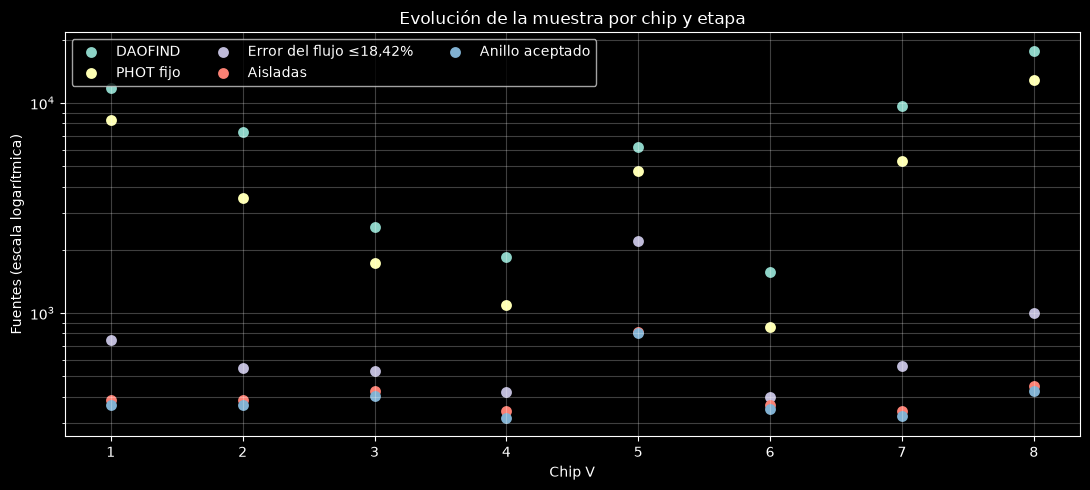

In [3]:
etapas = df[['chip','dao','apertura','anillo_valido','phot_validas','merr','aisladas','analizadas',
             'limpias','contaminadas','adapt_aceptadas','recuperadas','sin_solucion']].copy()
etapas.columns = ['Chip','DAOFIND','Apertura válida','Anillo válido / PHOT','MAG+error válidos',
                  'Error flujo ≤18,42%','Aisladas','Anillos evaluados','Cielo fijo limpio','Fijo contaminado',
                  'Anillo adaptativo aceptado','Recuperadas','Sin solución']
display(etapas.set_index('Chip'))

fig, ax = plt.subplots(figsize=(11,5))
for clave, etiqueta in [('dao','DAOFIND'),('anillo_valido','PHOT fijo'),('merr','Error del flujo ≤18,42%'),
                        ('aisladas','Aisladas'),('adapt_aceptadas','Anillo aceptado')]:
    ax.scatter(df['chip'],df[clave],marker='o',linewidth=1.8,label=etiqueta)
ax.set_yscale('log')
ax.set_xticks(df['chip'])
ax.set_xlabel('Chip V')
ax.set_ylabel('Fuentes (escala logarítmica)')
ax.set_title('Evolución de la muestra por chip y etapa')
ax.grid(alpha=.25,which='both')
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

## 5. Calidad de imagen y threshold

El valor `threshold` es el parámetro obtenido del ajuste por chip, no un umbral universal de completitud. Los valores de FWHM de los chips 1–2 proceden de medidas manuales y los de 3–8 de selección/ajuste automático.

,modo,estrellas_muestra,cajas_cielo,fwhm,sigma_sky,threshold,r2,radio_apertura,radio_cielo_int,radio_cielo_ext
chip,,,,,,,,,,
1,Manual IRAF,8,16,4.51,3.16,3.5500,0.9985,13.53,22.55,37.55
2,Manual IRAF,6,22,4.52,3.62,3.8300,0.9984,13.56,22.60,37.60
3,Automático,15,15,4.62,3.17,4.3224,0.9980,13.86,23.10,38.10
4,Automático,15,15,4.61,3.23,4.4375,0.9981,13.83,23.05,38.05
5,Automático,15,15,4.48,3.20,3.7232,0.9987,13.44,22.40,37.40
6,Automático,15,15,4.62,3.42,4.4482,0.9984,13.86,23.10,38.10
7,Automático,15,15,4.42,3.34,3.7811,0.9980,13.26,22.10,37.10
8,Automático,15,15,4.48,3.11,3.1833,0.9982,13.44,22.40,37.40


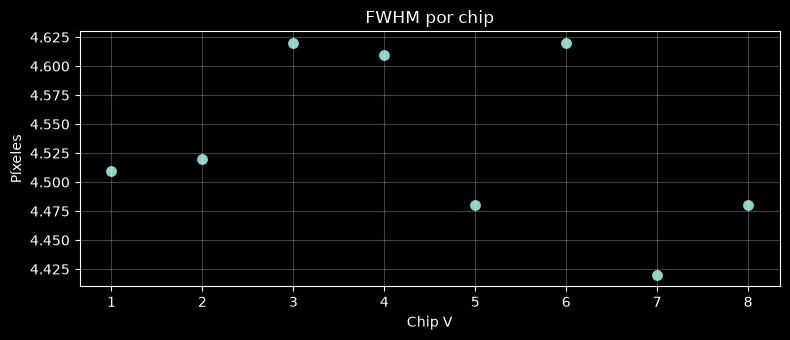

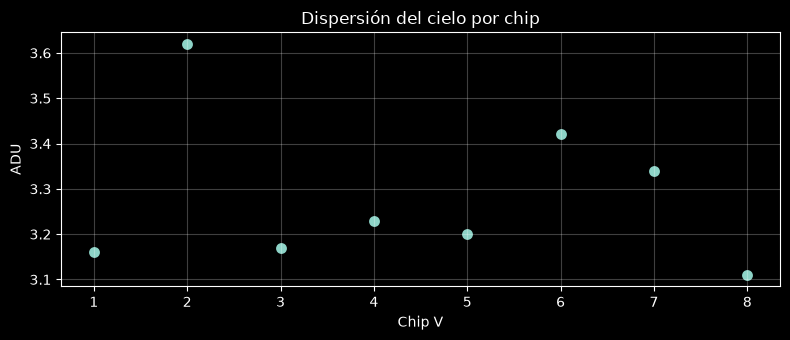

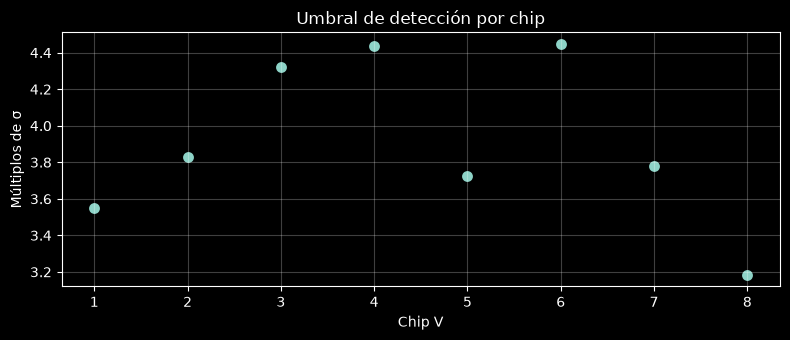

In [4]:
parametros = df[['chip','modo','estrellas_muestra','cajas_cielo','fwhm','sigma_sky','threshold','r2','radio_apertura','radio_cielo_int','radio_cielo_ext']].copy()
display(parametros.round(4).set_index('chip'))

for y, titulo, unidad in [
    ('fwhm','FWHM por chip','Píxeles'),
    ('sigma_sky','Dispersión del cielo por chip','ADU'),
    ('threshold','Umbral de detección por chip','Múltiplos de σ')
]:
    fig,ax=plt.subplots(figsize=(8,3.5))
    ax.scatter(df['chip'],df[y],marker='o',linewidth=1.8)
    ax.set_xticks(df['chip']);ax.set_xlabel('Chip V');ax.set_ylabel(unidad)
    ax.set_title(titulo);ax.grid(alpha=.25)
    plt.tight_layout();plt.show()

## 6. Recuperación de anillos contaminados

,aisladas,limpias,contaminadas,recuperadas,sin_solucion,adapt_aceptadas,recuperacion_pct,aceptacion_pct
chip,,,,,,,,
1,385,323,62,43,19,366,69.35,95.06
2,387,321,66,45,21,366,68.18,94.57
3,424,353,71,51,20,404,71.83,95.28
4,341,283,58,33,25,316,56.90,92.67
5,814,789,24,18,7,807,75.00,99.14
6,365,302,63,49,14,351,77.78,96.16
7,340,282,58,42,16,324,72.41,95.29
8,448,384,64,41,23,425,64.06,94.87


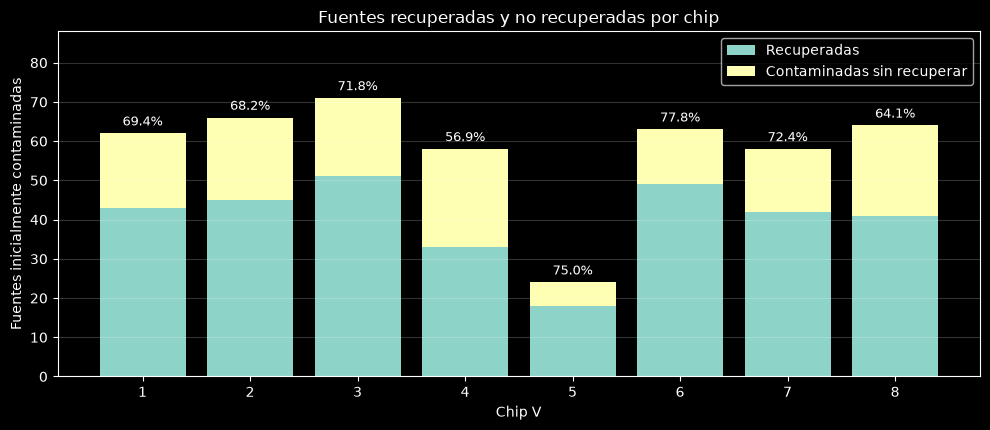

In [5]:
tabla_rec = df[['chip','aisladas','limpias','contaminadas','recuperadas','sin_solucion',
                'adapt_aceptadas','recuperacion_pct','aceptacion_pct']].copy()
display(tabla_rec.round(2).set_index('chip'))

fig,ax=plt.subplots(figsize=(10,4.4))
ax.bar(df['chip'],df['recuperadas'],label='Recuperadas')
ax.bar(df['chip'],df['contaminadas']-df['recuperadas'],bottom=df['recuperadas'],label='Contaminadas sin recuperar')
for chip,numero,porcentaje in zip(df.chip,df.contaminadas,df.recuperacion_pct):
    ax.text(chip,numero+2,f'{porcentaje:.1f}%',ha='center',fontsize=9)
ax.set_xticks(df['chip']);ax.set_xlabel('Chip V');ax.set_ylabel('Fuentes inicialmente contaminadas')
ax.set_title('Fuentes recuperadas y no recuperadas por chip')
ax.legend();ax.grid(axis='y',alpha=.2);ax.set_ylim(0,df.contaminadas.max()+17)
plt.tight_layout();plt.show()

## 7. Distribución del anillo seleccionado

Para los cinco anillos considerados, la primera columna representa el anillo original; las demás corresponden a desplazamientos de 5, 10, 15 y 20 píxeles del radio interior.

,Inicial (+0),+5 pix,+10 pix,+15 pix,+20 pix,Total
Chip,,,,,,
1,323,17,7,8,11,366
2,321,17,5,12,11,366
3,353,16,18,8,9,404
4,283,8,11,8,6,316
5,789,9,4,2,3,807
6,302,18,16,9,6,351
7,282,8,15,14,5,324
8,384,19,8,10,4,425


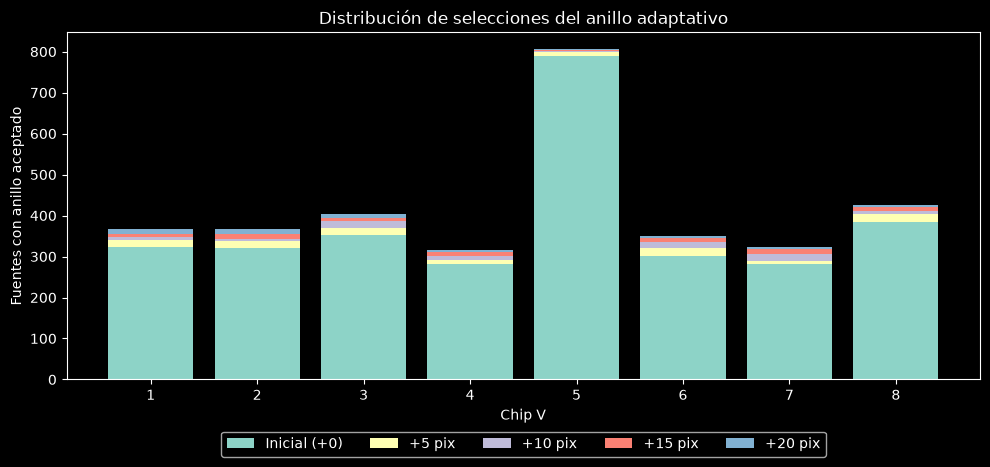

In [6]:
matriz=np.array(df['anillos'].tolist(),dtype=int)
tabla_anillos=pd.DataFrame(matriz,columns=['Inicial (+0)','+5 pix','+10 pix','+15 pix','+20 pix'],index=df['chip'])
tabla_anillos.index.name='Chip'
display(tabla_anillos.assign(Total=tabla_anillos.sum(axis=1)))
fig,ax=plt.subplots(figsize=(10,4.8))
fondo=np.zeros(len(df),dtype=int)
for j,col in enumerate(tabla_anillos.columns):
    ax.bar(df['chip'],matriz[:,j],bottom=fondo,label=col)
    fondo+=matriz[:,j]
ax.set_xticks(df['chip']);ax.set_xlabel('Chip V');ax.set_ylabel('Fuentes con anillo aceptado')
ax.set_title('Distribución de selecciones del anillo adaptativo')
ax.legend(ncol=5,loc='upper center',bbox_to_anchor=(.5,-.13))
plt.tight_layout();plt.show()

## 8. Contaminación del cielo: antes y después

Los porcentajes corresponden a **medianas calculadas solo entre las fuentes desplazadas**. La mediana del cambio pareado no tiene que coincidir con la resta de las dos medianas. El límite de Tukey $f_{\rm lim}$ se estima independientemente para cada chip.

,f_lim_pct,fout_inicial_pct,fout_final_pct,reduccion_fout_med_pp,pct_fout_reduce
chip,,,,,
1,2.070,4.512,1.344,2.889,100.0
2,1.796,3.036,1.199,1.986,100.0
3,1.821,2.916,1.254,1.840,100.0
4,1.514,3.096,0.838,2.486,100.0
5,10.002,11.526,8.542,2.755,100.0
6,1.418,3.018,0.941,2.092,100.0
7,1.748,4.910,1.187,4.118,100.0
8,3.668,5.709,2.553,3.615,100.0


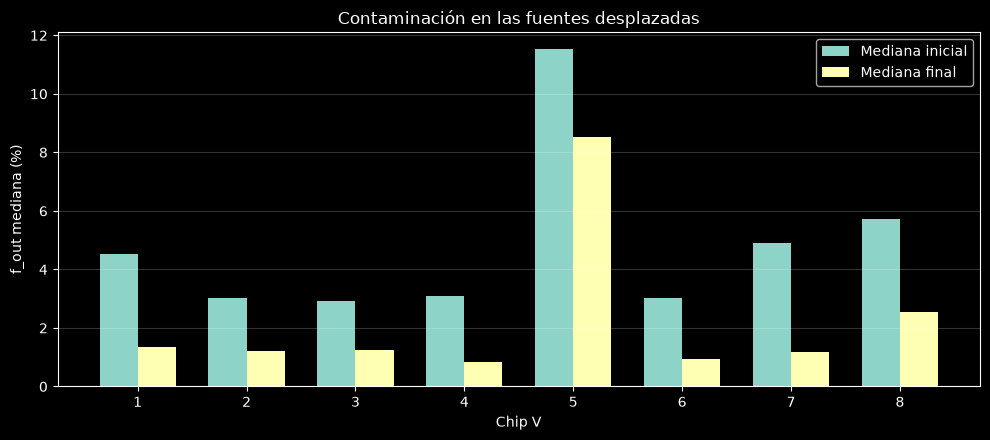

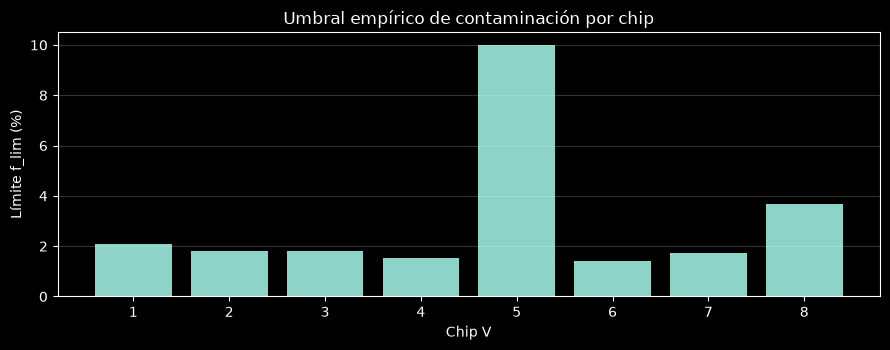

In [7]:
contaminacion=df[['chip','f_lim_pct','fout_inicial_pct','fout_final_pct','reduccion_fout_med_pp','pct_fout_reduce']].copy()
display(contaminacion.round(3).set_index('chip'))

fig,ax=plt.subplots(figsize=(10,4.5))
w=.35
ax.bar(df.chip-w/2,df.fout_inicial_pct,width=w,label='Mediana inicial')
ax.bar(df.chip+w/2,df.fout_final_pct,width=w,label='Mediana final')
ax.set_xticks(df.chip);ax.set_xlabel('Chip V');ax.set_ylabel('f_out mediana (%)')
ax.set_title('Contaminación en las fuentes desplazadas')
ax.legend();ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(9,3.6))
ax.bar(df['chip'],df['f_lim_pct'])
ax.set_xticks(df.chip);ax.set_xlabel('Chip V');ax.set_ylabel('Límite f_lim (%)')
ax.set_title('Umbral empírico de contaminación por chip')
ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()

## 9. Calidad fotométrica expresada en porcentaje de flujo

Las métricas proceden de las fuentes **con anillo desplazado y fotometría válida en las soluciones fija y adaptativa**. La tabla presenta la **incertidumbre relativa mediana del flujo (%)**, equivalente a los valores MERR originales de IRAF. También indica el porcentaje de fuentes cuya incertidumbre individual disminuyó.

La columna de **cambio del flujo (%)** describe cuánto difieren las dos soluciones, **no** un error porcentual respecto al valor verdadero. Del mismo modo, $\Delta MAG$ es una diferencia de magnitudes, expresada legítimamente en mag; no se debe confundir con incertidumbre.

**Precaución al comparar medianas:** una reducción en la mediana del error no significa que todas las estrellas mejoren; por eso también se conserva el porcentaje de mejoras individuales. La reducción relativa (%) y la reducción en puntos porcentuales (pp) tampoco son la misma cantidad.

,N desplazadas,Error flujo fijo (%),Error flujo adaptativo (%),Reducción error (pp),Reducción relativa mediana (%),Fuentes con menor error (%),SNR fijo (mediana),SNR adaptativo (mediana),Cambio de flujo (%),ΔMAG (mag),|ΔMAG| (mag),ΔMSKY (ADU),ΔSTDEV (ADU)
Chip,,,,,,,,,,,,,
1,43,2.855,2.671,0.184,6.452,55.814,35.023,37.438,0.363,-0.004,0.019,-0.165,-0.064
2,45,3.224,2.947,0.276,8.571,62.222,31.020,33.928,0.924,-0.010,0.019,-0.090,-0.102
3,51,3.868,3.684,0.184,4.762,70.588,25.850,27.142,0.369,-0.004,0.018,-0.077,-0.091
4,33,3.868,3.039,0.829,21.429,51.515,25.850,32.900,0.144,-0.002,0.018,-0.067,-0.076
5,18,5.112,4.329,0.783,15.315,66.667,19.576,23.110,0.619,-0.007,0.041,-0.058,-0.053
6,49,2.855,2.671,0.184,6.452,71.429,35.023,37.438,0.580,-0.006,0.018,-0.072,-0.081
7,42,5.020,4.651,0.368,7.339,69.048,19.923,21.501,0.837,-0.009,0.021,-0.097,-0.125
8,41,3.684,3.684,0.000,0.000,65.854,27.143,27.143,1.210,-0.013,0.021,-0.068,-0.090


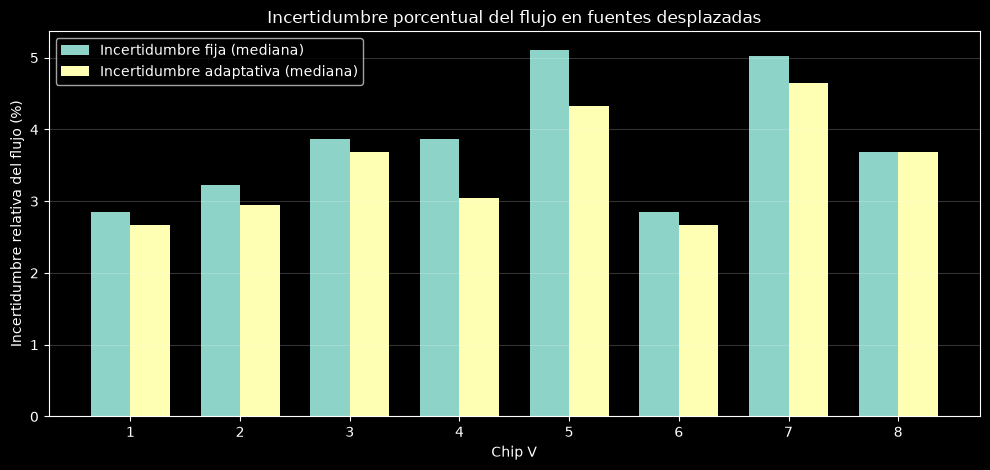

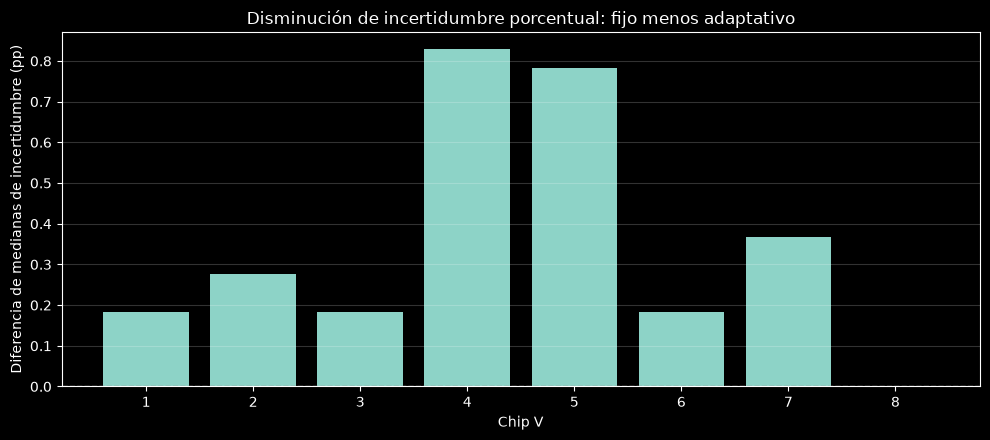

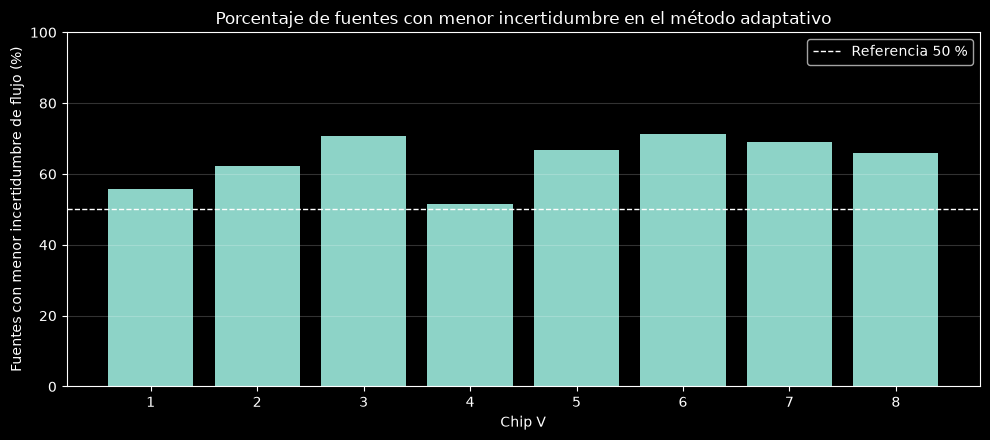

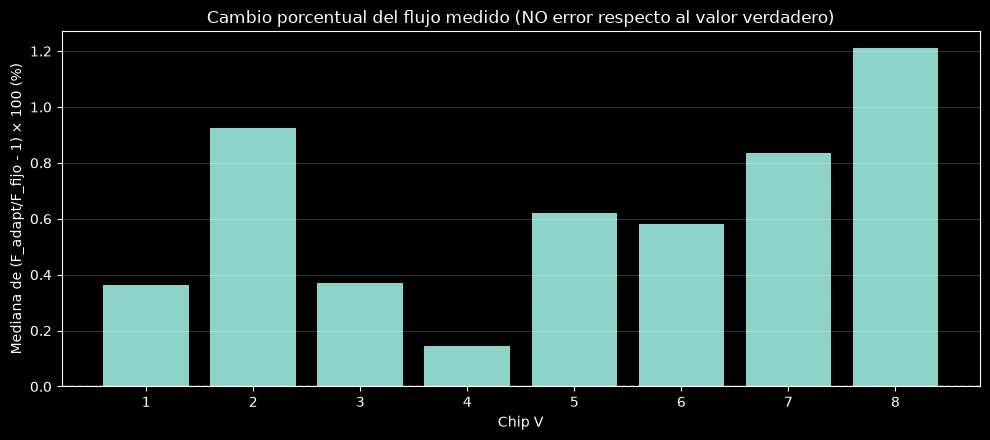

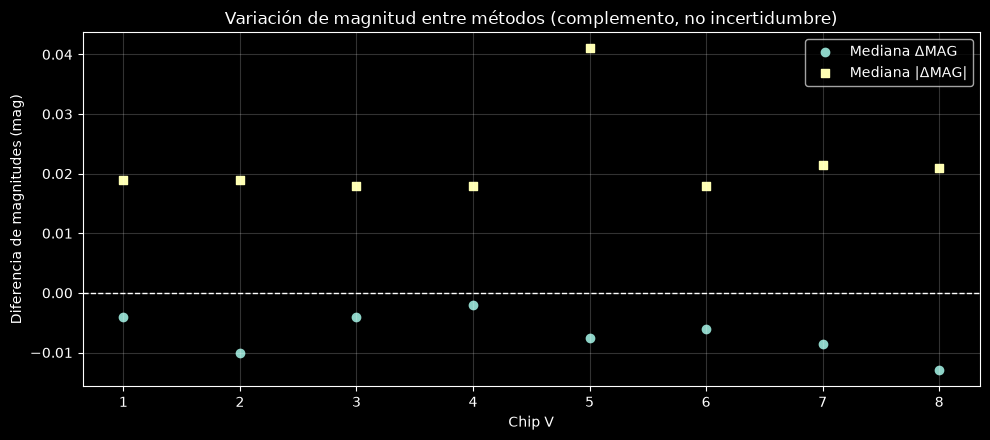

In [8]:
# Todos los indicadores de incertidumbre se muestran en % del flujo.
tabla_foto = df[[
    'chip','movidas_validas','err_flujo_fijo_pct','err_flujo_adapt_pct',
    'reduccion_err_flujo_pp','reduccion_err_flujo_rel_pct','pct_mejora_merr',
    'snr_fijo','snr_adapt','cambio_flujo_med_pct','delta_mag','abs_delta_mag',
    'delta_msky','delta_stdev'
]].rename(columns={
    'chip': 'Chip',
    'movidas_validas': 'N desplazadas',
    'err_flujo_fijo_pct': 'Error flujo fijo (%)',
    'err_flujo_adapt_pct': 'Error flujo adaptativo (%)',
    'reduccion_err_flujo_pp': 'Reducción error (pp)',
    'reduccion_err_flujo_rel_pct': 'Reducción relativa mediana (%)',
    'pct_mejora_merr': 'Fuentes con menor error (%)',
    'snr_fijo': 'SNR fijo (mediana)',
    'snr_adapt': 'SNR adaptativo (mediana)',
    'cambio_flujo_med_pct': 'Cambio de flujo (%)',
    'delta_mag': 'ΔMAG (mag)',
    'abs_delta_mag': '|ΔMAG| (mag)',
    'delta_msky': 'ΔMSKY (ADU)',
    'delta_stdev': 'ΔSTDEV (ADU)',
})
display(tabla_foto.set_index('Chip').round(3))

fig, ax = plt.subplots(figsize=(10,4.8))
w = .36
ax.bar(df['chip']-w/2,df['err_flujo_fijo_pct'],width=w,label='Incertidumbre fija (mediana)')
ax.bar(df['chip']+w/2,df['err_flujo_adapt_pct'],width=w,label='Incertidumbre adaptativa (mediana)')
ax.set_xticks(df.chip);ax.set_xlabel('Chip V')
ax.set_ylabel('Incertidumbre relativa del flujo (%)')
ax.set_title('Incertidumbre porcentual del flujo en fuentes desplazadas')
ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()

fig, ax = plt.subplots(figsize=(10,4.5))
ax.bar(df['chip'],df['reduccion_err_flujo_pp'])
ax.axhline(0,color='gray',linestyle='--',linewidth=1)
ax.set_xticks(df.chip);ax.set_xlabel('Chip V')
ax.set_ylabel('Diferencia de medianas de incertidumbre (pp)')
ax.set_title('Disminución de incertidumbre porcentual: fijo menos adaptativo')
ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()

fig, ax = plt.subplots(figsize=(10,4.5))
ax.bar(df['chip'],df['pct_mejora_merr'])
ax.axhline(50,linestyle='--',linewidth=1,label='Referencia 50 %')
ax.set_xticks(df.chip);ax.set_ylim(0,100);ax.set_xlabel('Chip V')
ax.set_ylabel('Fuentes con menor incertidumbre de flujo (%)')
ax.set_title('Porcentaje de fuentes con menor incertidumbre en el método adaptativo')
ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()

fig, ax = plt.subplots(figsize=(10,4.5))
ax.bar(df['chip'],df['cambio_flujo_med_pct'])
ax.axhline(0,linestyle='--',linewidth=1)
ax.set_xticks(df.chip);ax.set_xlabel('Chip V')
ax.set_ylabel('Mediana de (F_adapt/F_fijo - 1) × 100 (%)')
ax.set_title('Cambio porcentual del flujo medido (NO error respecto al valor verdadero)')
ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()

# Conservar la comparación en magnitudes como métrica complementaria.
fig, ax = plt.subplots(figsize=(10,4.5))
ax.scatter(df['chip'],df['delta_mag'],marker='o',label='Mediana ΔMAG')
ax.scatter(df['chip'],df['abs_delta_mag'],marker='s',label='Mediana |ΔMAG|')
ax.axhline(0,linestyle='--',linewidth=1)
ax.set_xticks(df.chip);ax.set_xlabel('Chip V');ax.set_ylabel('Diferencia de magnitudes (mag)')
ax.set_title('Variación de magnitud entre métodos (complemento, no incertidumbre)')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()


## 10. Control de coherencia de los resultados

Las comprobaciones se hacen sobre los **conteos reportados**. Una salida coherente no reemplaza la revisión de las imágenes de selección ni de los archivos de IRAF.

In [9]:
chequeos = pd.DataFrame({
    'Chip': df.chip,
    'PHOT == anillo válido': df.phot_total.eq(df.anillo_valido),
    'MAG/error ≤ PHOT': df.phot_validas.le(df.phot_total),
    'Error ≤ válidas': df.merr.le(df.phot_validas),
    'Clasificación suma evaluadas': df.limpias.add(df.contaminadas).eq(df.analizadas),
    'Aceptadas = limpias + recuperadas': df.adapt_aceptadas.eq(df.limpias+df.recuperadas),
    'Recuperadas ≤ contaminadas': df.recuperadas.le(df.contaminadas),
    'Grupos = aceptadas': pd.Series([sum(a)==n for a,n in zip(df.anillos,df.adapt_aceptadas)]),
    'Control = limpias': df.control.eq(df.limpias),
    'Desplazadas válidas = recuperadas': df.movidas_validas.eq(df.recuperadas),
    'Match exacto': df.match_max.eq(0),
    'Control Δ=0': df.control_delta_max.eq(0),
    'Aisladas = evaluadas': df.aisladas.eq(df.analizadas),
})
display(chequeos.set_index('Chip'))
print('Alertas:')
for _,r in df.iterrows():
    if r.aisladas != r.analizadas:
        print(f'  Chip {int(r.chip)}: aisladas={r.aisladas}, anillos fijos evaluados={r.analizadas}; diferencia={int(r.aisladas-r.analizadas)}.')
    if r.f_lim_pct > 5:
        print(f'  Chip {int(r.chip)}: límite de Tukey inusualmente elevado: {r.f_lim_pct:.2f}% (revisar poblaciones/selección).')
print('Nota: reducir la mediana de incertidumbre (%) no demuestra precisión o exactitud absoluta.')
print('Las diferencias de medianas de contaminación pueden no coincidir con las medianas pareadas.')

,PHOT == anillo válido,MAG/error ≤ PHOT,Error ≤ válidas,Clasificación suma evaluadas,Aceptadas = limpias + recuperadas,Recuperadas ≤ contaminadas,Grupos = aceptadas,Control = limpias,Desplazadas válidas = recuperadas,Match exacto,Control Δ=0,Aisladas = evaluadas
Chip,,,,,,,,,,,,
1,True,True,True,True,True,True,True,True,True,True,True,True
2,True,True,True,True,True,True,True,True,True,True,True,True
3,True,True,True,True,True,True,True,True,True,True,True,True
4,True,True,True,True,True,True,True,True,True,True,True,True
5,True,True,True,True,True,True,True,True,True,True,True,False
6,True,True,True,True,True,True,True,True,True,True,True,True
7,True,True,True,True,True,True,True,True,True,True,True,True
8,True,True,True,True,True,True,True,True,True,True,True,True


Alertas:
  Chip 5: aisladas=814, anillos fijos evaluados=813; diferencia=1.
  Chip 5: límite de Tukey inusualmente elevado: 10.00% (revisar poblaciones/selección).
Nota: reducir la mediana de incertidumbre (%) no demuestra precisión o exactitud absoluta.
Las diferencias de medianas de contaminación pueden no coincidir con las medianas pareadas.


## 11. Comentarios por chip

**Chip 1 (supervisado):** 62 anillos inicialmente contaminados; 43 recuperados (**69,35 %**). Las 323 estrellas de control no cambiaron. La mediana $|\Delta MAG|$ fue **0,019 mag**.

**Chip 2 (supervisado):** 66 contaminados; 45 recuperados (**68,18 %**). Control de 321 fuentes con diferencias nulas. La mediana $|\Delta MAG|$ fue **0,019 mag**.

**Chip 3 (automatizado):** 71 contaminados; 51 recuperados (**71,83 %**). El grupo de control comprende 353 fuentes; las 51 desplazadas tuvieron datos fotométricos válidos.

**Chip 4 (automatizado):** 58 contaminados; 33 recuperados (**56,90 %**), el porcentaje de recuperación más bajo de la serie.

**Chip 5 (automatizado, ubicación principal de Sextans A):** 24 contaminados; 18 recuperados (**75,00 %**) **según el límite específico del chip**. Para esas 18 fuentes, la incertidumbre relativa mediana del flujo pasa de **5,11 % (anillo fijo)** a **4,33 % (adaptativo)**, y **66,67 %** muestran una reducción individual. Sin embargo, el límite $f_{\rm lim}$ es **10,00 %**, frente a aproximadamente 1,42–3,67 % en los otros chips. Además, el log registra **814 estrellas aisladas** y **813 anillos fijos analizados**; requiere revisión de esa fuente faltante antes de cerrar la interpretación.

**Chip 6 (automatizado):** 63 contaminados; 49 recuperados (**77,78 %**), el mayor porcentaje de recuperación registrado.

**Chip 7 (automatizado):** 58 contaminados; 42 recuperados (**72,41 %**). El FWHM reportado fue de 4,42 píxeles.

**Chip 8 (automatizado):** 64 contaminados; 41 recuperados (**64,06 %**). Presenta el mayor número inicial de detecciones: 17.735.

## 12. Discusión integrada y límites de la inferencia

**Eficacia operacional.** El método seleccionó nuevos anillos aceptables para parte de las fuentes cuyos anillos iniciales excedían el límite de contaminación definido **en cada chip**. Por construcción, la reducción de $f_{\rm out}$ valida el criterio operativo, no la exactitud física de la resta de fondo.

**Reproducibilidad del control.** Los resultados reportan distancia máxima de asociación igual a cero y diferencias nulas para las estrellas que mantienen el anillo. Esto apoya la consistencia interna de las ejecuciones.

**Incertidumbre porcentual del flujo.** El error porcentual reportado aquí se obtiene mediante $100\sigma_F/F\simeq 92.1034\,\mathrm{MERR}$. No se midió el porcentaje de desviación frente al flujo verdadero porque no hay un catálogo de referencia calibrado en este resumen. La proporción de fuentes cuya incertidumbre baja debe considerarse por chip; no se calcula una mediana global a partir de medianas por chip.

**Interpretación de otros porcentajes.** El porcentaje de **contaminación** del anillo $100 f_{\rm out}$ y el porcentaje de **incertidumbre fotométrica** $100\sigma_F/F$ tienen denominadores y significados físicos diferentes: no se pueden comparar numéricamente como si fuesen la misma medida.

**Sextans A en el Chip 5.** Allí el umbral de contaminación $f_{\rm lim}\approx10\%$ es marcadamente mayor que en el resto de los chips. Puede reflejar estructura del fondo y densidad de fuentes asociadas a la región galáctica, pero se necesita inspección visual y un análisis local específico. Su incertidumbre formal adaptativa menor no demuestra que la sustracción de luz difusa de la galaxia sea más exacta.

**Comparabilidad.** Chips 1–2 tuvieron selección supervisada de estrellas y cielo; chips 3–8 usaron selección automática distribuida. No se midió completitud contra un catálogo de referencia. Los resultados corresponden solo a las fuentes que cumplieron los filtros de calidad y aislamiento.

**Revisión pendiente.** Inspeccionar `V_chipN_auto_control.png` de los chips 3–8, verificar por qué el Chip 5 registra 814 aisladas frente a 813 anillos evaluados, y evaluar específicamente el fondo galáctico antes de afirmar mejora de exactitud.

## 13. Exportación opcional

La celda siguiente permite guardar la tabla completa en el directorio desde el que se ejecuta Jupyter. Está **desactivada por defecto**, para que la ejecución no modifique tus archivos sin que lo decidas.

In [10]:
# Descomenta cuando desees exportar desde tu propio notebook:
# df.drop(columns=['anillos']).to_csv('resumen_sextans_V_chips_1_8_error_porcentual.csv', index=False)

print('El resumen se ha calculado con los datos incorporados. No se escribieron archivos locales.')

El resumen se ha calculado con los datos incorporados. No se escribieron archivos locales.
